# Day 17 — Python Profiling & Performance Optimization for Data Science

**Fase 1 — Python Basics · Dia 17/28 · 30/10/2026**

Neste notebook eu estudo como **medir antes de otimizar**: encontrar gargalos de tempo e memória com as ferramentas da biblioteca padrão e aplicar as otimizações que mais importam em Data Science.

### Objetivos de aprendizagem
- Medir tempo com `timeit`, `time.perf_counter`, `cProfile` e `pstats`.
- Construir um *line profiler* simples com `sys.settrace` (sem instalar pacotes extras).
- Rastrear memória com `tracemalloc` e `sys.getsizeof`.
- Comparar loops Python × NumPy vectorizado (TF-IDF, cosseno, normalização, strings).
- Aplicar boas práticas de performance no pandas (`apply`, `itertuples`, categoricals, `query`).
- Escolher estruturas de dados eficientes (dict/set/heapq) para tarefas de NLP.
- Fazer o profiling de um pipeline scikit-learn completo com `load_digits`.

### Datasets reais usados
- `sklearn`: `load_digits`, `fetch_20newsgroups` (3 categorias, sem cabeçalhos)
- `seaborn`: `tips`, `titanic`

> ⚠️ **Nota:** todos os tempos são dependentes da máquina. O que importa são as **ordens de grandeza** e os *speedups* relativos, não os valores absolutos.

In [1]:
import cProfile
import functools
import heapq
import io
import pstats
import re
import sys
import time
import timeit
import tracemalloc
from array import array
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import cdist
from sklearn.datasets import fetch_20newsgroups, load_digits

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)

# Real text corpus: three 20 Newsgroups categories, headers/footers/quotes removed
news = fetch_20newsgroups(
    subset="train",
    categories=["sci.space", "rec.autos", "comp.graphics"],
    remove=("headers", "footers", "quotes"),
)
corpus = [doc for doc in news.data if doc.strip()]
digits = load_digits()
tips = sns.load_dataset("tips")
titanic = sns.load_dataset("titanic")

# Global registry of benchmark results, used for the final speedup charts
BENCH: dict[str, dict[str, float]] = {}

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__}")
print(f"20 Newsgroups docs: {len(corpus)} | digits: {digits.data.shape} | tips: {tips.shape} | titanic: {titanic.shape}")

Python 3.11.17 | NumPy 1.26.4 | pandas 2.3.3
20 Newsgroups docs: 1710 | digits: (1797, 64) | tips: (244, 7) | titanic: (891, 15)


## Seção 1 — Introdução ao Profiling

**Profiling** é medir *onde* um programa gasta tempo e memória. Em Data Science isso importa porque:

- pipelines rodam sobre milhares/milhões de linhas — um loop ineficiente multiplica o custo;
- o gargalo raramente está onde imaginamos (*"premature optimization is the root of all evil"* — Knuth);
- otimizar sem medir leva a código mais complexo sem ganho real.

Fluxo de trabalho: **medir → identificar o gargalo → otimizar só ele → medir de novo → validar que o resultado não mudou.**

| Ferramenta | Pergunta que responde |
|---|---|
| `timeit` | Quanto tempo leva um trecho pequeno? |
| `cProfile` | Quais funções consomem mais tempo no programa todo? |
| `pstats` | Como ordenar/filtrar o relatório do `cProfile`? |
| `tracemalloc` | Onde a memória está sendo alocada? |

In [2]:
def bench(stmt, number: int = 5, repeat: int = 3) -> float:
    """Return the best mean time per call (seconds) for a zero-arg callable."""
    return min(timeit.repeat(stmt, number=number, repeat=repeat)) / number

pixels = digits.data.ravel().tolist()     # 1797 * 64 real pixel intensities
pixels_np = digits.data.ravel()

def sum_squares_loop(values):
    """Sum of squares with an explicit Python loop."""
    total = 0.0
    for v in values:
        total += v * v
    return total

def sum_squares_comp(values):
    """Sum of squares with a generator expression."""
    return sum(v * v for v in values)

def sum_squares_numpy(values):
    """Sum of squares with a vectorized dot product."""
    return float(values @ values)

assert sum_squares_loop(pixels) == sum_squares_comp(pixels) == sum_squares_numpy(pixels_np)

t = {
    "python loop": bench(lambda: sum_squares_loop(pixels), number=10),
    "comprehension": bench(lambda: sum_squares_comp(pixels), number=10),
    "numpy": bench(lambda: sum_squares_numpy(pixels_np), number=200),
}
BENCH["sum of squares (digits pixels)"] = t
for k, v in t.items():
    print(f"{k:<14}: {v*1e3:8.3f} ms  (speedup vs loop: {t['python loop']/v:7.1f}x)")

python loop   :    2.880 ms  (speedup vs loop:     1.0x)
comprehension :    2.646 ms  (speedup vs loop:     1.1x)
numpy         :    0.196 ms  (speedup vs loop:    14.7x)


In [3]:
TOKEN_RE = re.compile(r"[a-z]+")
STOPWORDS = {"the", "a", "an", "and", "or", "of", "to", "in", "is", "it", "that",
             "for", "on", "with", "as", "this", "be", "are", "was", "i", "you", "have"}

def tokenize(text: str) -> list[str]:
    """Lowercase and extract alphabetic tokens."""
    return TOKEN_RE.findall(text.lower())

def remove_stopwords_slow(tokens: list[str]) -> list[str]:
    """Deliberately slow: membership test against a list (O(n) per lookup)."""
    stop_list = sorted(STOPWORDS)
    return [t for t in tokens if t not in stop_list]

def word_frequencies(docs: list[str]) -> Counter:
    """Tokenize, drop stopwords and count words across a corpus."""
    counts = Counter()
    for doc in docs:
        counts.update(remove_stopwords_slow(tokenize(doc)))
    return counts

profiler = cProfile.Profile()
profiler.enable()
freqs = word_frequencies(corpus)
profiler.disable()
print("Top 10 words:", freqs.most_common(10))

Top 10 words: [('s', 1698), ('t', 1383), ('if', 1294), ('from', 1268), ('not', 1251), ('at', 1221), ('but', 1194), ('can', 1167), ('space', 1060), ('by', 1027)]


In [4]:
stream = io.StringIO()
stats = pstats.Stats(profiler, stream=stream).strip_dirs()

stats.sort_stats(pstats.SortKey.CUMULATIVE).print_stats(8)
print(stream.getvalue()[:2500])

# Programmatic access: turn pstats into a DataFrame for easier analysis
rows = []
for (filename, line, func), (cc, nc, tottime, cumtime, _) in stats.stats.items():
    rows.append({"function": func, "ncalls": nc, "tottime_s": tottime, "cumtime_s": cumtime})
prof_df = pd.DataFrame(rows).sort_values("tottime_s", ascending=False).head(8)
prof_df

         18855 function calls in 0.134 seconds

   Ordered by: cumulative time
   List reduced from 32 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.134    0.067 interactiveshell.py:3786(run_code)
        2    0.000    0.000    0.134    0.067 {built-in method builtins.exec}
        1    0.005    0.005    0.134    0.134 989753775.py:14(word_frequencies)
     1710    0.001    0.000    0.070    0.000 989753775.py:9(remove_stopwords_slow)
     1710    0.067    0.000    0.067    0.000 989753775.py:12(<listcomp>)
     1710    0.001    0.000    0.040    0.000 989753775.py:5(tokenize)
     1710    0.037    0.000    0.037    0.000 {method 'findall' of 're.Pattern' objects}
     1711    0.001    0.000    0.019    0.000 __init__.py:660(update)





,function,ncalls,tottime_s,cumtime_s
4,<listcomp>,1710,0.0672,0.0672
29,<method 'findall' of 're.Pattern' objects>,1710,0.0374,0.0374
28,<built-in method _collections._count_elements>,1710,0.0164,0.0164
7,word_frequencies,1,0.0049,0.1335
27,<built-in method builtins.sorted>,1710,0.0016,0.0016
21,<method 'lower' of 'str' objects>,1710,0.0016,0.0016
6,remove_stopwords_slow,1710,0.0012,0.0700
5,tokenize,1710,0.0009,0.0398


### Interpretando o relatório do `cProfile`

- **`ncalls`** — número de chamadas. Valores enormes indicam funções chamadas dentro de loops.
- **`tottime`** — tempo gasto *dentro* da função, excluindo subchamadas → aponta o gargalo real.
- **`cumtime`** — tempo total, incluindo subchamadas → mostra qual etapa de alto nível é cara.
- **`percall`** — `tottime/ncalls` ou `cumtime/ncalls`.

📌 No exemplo, `remove_stopwords_slow` domina o `tottime`: a busca `t not in stop_list` é **O(n)** por token e a lista é reordenada a cada documento. Trocar por um `set` (Seção 5) resolve. Note também que o próprio `cProfile` adiciona *overhead* — use-o para achar gargalos, e `timeit` para medir o ganho final.

## Seção 2 — Profiling linha a linha e de memória

O `cProfile` trabalha no nível de **função**. Às vezes precisamos saber **qual linha** dentro de uma função é cara. O pacote `line_profiler` faz isso, mas aqui eu construo uma versão didática usando apenas `sys.settrace`, que permite registrar um *callback* a cada linha executada.

Para memória, a biblioteca padrão oferece:
- `tracemalloc` — rastreia alocações feitas pelo Python, com *snapshots* comparáveis;
- `sys.getsizeof` — tamanho *raso* (shallow) de um objeto.

In [5]:
def line_profile(func):
    """Minimal line profiler built on sys.settrace (didactic version of line_profiler).

    Accumulates wall time per source line of `func` and prints a report.
    """
    code_obj = func.__code__

    @functools.wraps(func)
    def wrapper(*args, **kwargs):
        timings: dict[int, float] = {}
        hits: dict[int, int] = {}
        state = {"line": None, "t": None}

        def tracer(frame, event, arg):
            if frame.f_code is not code_obj:
                return None                      # don't trace nested calls
            now = time.perf_counter()
            if state["line"] is not None:
                timings[state["line"]] = timings.get(state["line"], 0.0) + now - state["t"]
            if event == "line":
                hits[frame.f_lineno] = hits.get(frame.f_lineno, 0) + 1
                state["line"], state["t"] = frame.f_lineno, now
            else:
                state["line"] = None
            return tracer

        sys.settrace(tracer)
        try:
            result = func(*args, **kwargs)
        finally:
            sys.settrace(None)

        import inspect
        src, start = inspect.getsourcelines(func)
        total = sum(timings.values()) or 1.0
        print(f"{'line':>5} {'hits':>7} {'time(ms)':>9} {'%':>6}  source")
        for offset, text in enumerate(src):
            ln = start + offset
            if ln in timings:
                print(f"{ln:>5} {hits.get(ln, 0):>7} {timings[ln]*1e3:>9.2f} {100*timings[ln]/total:>5.1f}%  {text.rstrip()}")
        return result
    return wrapper

@line_profile
def preprocess_docs(docs):
    cleaned = []
    for doc in docs:
        lowered = doc.lower()
        tokens = TOKEN_RE.findall(lowered)
        stop_list = sorted(STOPWORDS)
        kept = [t for t in tokens if t not in stop_list]
        cleaned.append(" ".join(kept))
    return cleaned

_ = preprocess_docs(corpus[:300])

 line    hits  time(ms)      %  source
   46       1      0.00   0.0%      cleaned = []
   47     301      0.14   0.5%      for doc in docs:
   48     300      0.43   1.6%          lowered = doc.lower()
   49     300      8.21  31.3%          tokens = TOKEN_RE.findall(lowered)
   50     300      0.37   1.4%          stop_list = sorted(STOPWORDS)
   51     300     16.12  61.4%          kept = [t for t in tokens if t not in stop_list]
   52     300      0.96   3.7%          cleaned.append(" ".join(kept))
   53       1      0.00   0.0%      return cleaned


In [6]:
def nlp_pipeline(docs):
    """Tokenize, build a vocabulary and a dense bag-of-words matrix (memory-hungry on purpose)."""
    tokenized = [tokenize(d) for d in docs]
    vocab = {w: i for i, w in enumerate(sorted({w for toks in tokenized for w in toks}))}
    bow = np.zeros((len(docs), len(vocab)), dtype=np.int64)
    for r, toks in enumerate(tokenized):
        for w in toks:
            bow[r, vocab[w]] += 1
    return tokenized, vocab, bow

tracemalloc.start()
snap_before = tracemalloc.take_snapshot()
tokenized, vocab, bow = nlp_pipeline(corpus[:600])
snap_after = tracemalloc.take_snapshot()
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

print(f"Vocabulary size: {len(vocab):,} | BoW shape: {bow.shape}")
print(f"Current traced memory: {current/1e6:.1f} MB | peak: {peak/1e6:.1f} MB\n")
print("Top allocation differences by line:")
for stat in snap_after.compare_to(snap_before, "lineno")[:5]:
    print(" ", stat)
print(f"\nDense BoW nbytes: {bow.nbytes/1e6:.1f} MB, non-zero share: {np.count_nonzero(bow)/bow.size:.3%}")

Vocabulary size: 13,075 | BoW shape: (600, 13075)
Current traced memory: 70.8 MB | peak: 70.9 MB

Top allocation differences by line:
  /tmp/ipykernel_1710/4151585101.py:5: size=59.9 MiB (+59.9 MiB), count=2 (+2), average=29.9 MiB
  /tmp/ipykernel_1710/989753775.py:7: size=7123 KiB (+7123 KiB), count=116350 (+116350), average=63 B
  /tmp/ipykernel_1710/4151585101.py:4: size=756 KiB (+756 KiB), count=12819 (+12819), average=60 B
  /tmp/ipykernel_1710/4151585101.py:3: size=5376 B (+5376 B), count=1 (+1), average=5376 B
  /tmp/ipykernel_1710/4151585101.py:12: size=3264 B (+3264 B), count=1 (+1), average=3264 B

Dense BoW nbytes: 62.8 MB, non-zero share: 0.762%


In [7]:
ages = titanic["age"].dropna()
ages_list = ages.tolist()

def deep_list_size(lst) -> int:
    """List container + every element object (getsizeof is shallow)."""
    return sys.getsizeof(lst) + sum(sys.getsizeof(x) for x in lst)

sizes = pd.Series({
    "list[float] (deep)": deep_list_size(ages_list),
    "array('d')": sys.getsizeof(array("d", ages_list)),
    "np.ndarray float64": sys.getsizeof(ages.to_numpy()),
    "np.ndarray float32": sys.getsizeof(ages.to_numpy(dtype=np.float32)),
    "pd.Series float64 (deep)": ages.memory_usage(deep=True),
}, name="bytes")
print(f"{len(ages_list)} real titanic ages")
sizes.to_frame().assign(relative=lambda d: d["bytes"] / d["bytes"].min())

714 real titanic ages


,bytes,relative
list[float] (deep),22904,7.7170
array('d'),5792,1.9515
np.ndarray float64,5824,1.9623
np.ndarray float32,2968,1.0000
pd.Series float64 (deep),11424,3.8491


### Quando usar cada ferramenta

| Situação | Ferramenta |
|---|---|
| Comparar duas implementações curtas | `timeit` (várias repetições, pegar o mínimo) |
| Programa lento e não sei por quê | `cProfile` + `pstats` (ordenar por `tottime`) |
| Função lenta e não sei qual linha | *line profiler* (aqui, versão com `sys.settrace`) |
| Consumo de memória alto / `MemoryError` | `tracemalloc` (snapshots + `compare_to`) |
| Tamanho de um objeto | `sys.getsizeof` (raso!) ou `Series.memory_usage(deep=True)` |

⚠️ `sys.getsizeof` em uma lista mede só o *container* (ponteiros). Para o tamanho real é preciso somar os elementos — por isso a função `deep_list_size`. Arrays NumPy guardam os valores **contíguos**, sem um objeto Python por número.

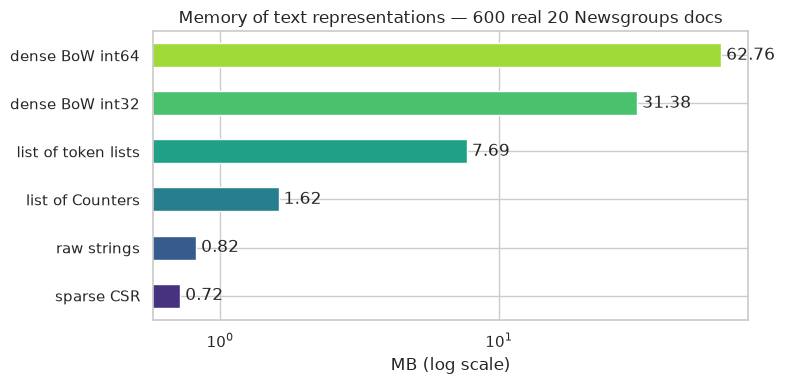

Dense/sparse ratio: 87x


In [8]:
from sklearn.feature_extraction.text import CountVectorizer

docs = corpus[:600]
tokens_nested = [tokenize(d) for d in docs]
counters = [Counter(t) for t in tokens_nested]
vec = CountVectorizer(token_pattern=r"[a-z]+")
X_sparse = vec.fit_transform(docs)

def sparse_nbytes(m) -> int:
    return m.data.nbytes + m.indices.nbytes + m.indptr.nbytes

mem = pd.Series({
    "raw strings": deep_list_size(docs),
    "list of token lists": sys.getsizeof(tokens_nested) + sum(deep_list_size(t) for t in tokens_nested),
    "list of Counters": sum(sys.getsizeof(c) for c in counters),
    "dense BoW int64": X_sparse.toarray().nbytes,
    "dense BoW int32": X_sparse.toarray().astype(np.int32).nbytes,
    "sparse CSR": sparse_nbytes(X_sparse),
}).sort_values() / 1e6

ax = mem.plot.barh(color=sns.color_palette("viridis", len(mem)), figsize=(8, 4))
ax.set_xlabel("MB (log scale)"); ax.set_xscale("log")
ax.set_title("Memory of text representations — 600 real 20 Newsgroups docs")
for i, v in enumerate(mem):
    ax.text(v, i, f" {v:.2f}", va="center")
plt.tight_layout(); plt.show()
print(f"Dense/sparse ratio: {mem['dense BoW int64'] / mem['sparse CSR']:.0f}x")

## Seção 3 — Otimização com NumPy Vectorization

**Vectorization** significa expressar a operação sobre o array inteiro, deixando o loop acontecer em código C compilado dentro do NumPy. Ganhos vêm de:

1. eliminar o *overhead* do interpretador por elemento;
2. memória contígua e tipada (cache-friendly);
3. instruções SIMD e bibliotecas BLAS otimizadas (`@`, `dot`).

A seguir, quatro exemplos de NLP/DS com dados reais, sempre verificando que o resultado vetorizado é **idêntico** ao do loop.

In [9]:
# Manual TF-IDF on a real count matrix (smooth idf, like sklearn: idf = ln((1+n)/(1+df)) + 1)
tf_vec = CountVectorizer(token_pattern=r"[a-z]+", max_features=400, stop_words="english")
counts = tf_vec.fit_transform(corpus[:400]).toarray().astype(np.float64)
n_docs, n_terms = counts.shape

def tfidf_loop(C):
    """TF-IDF with nested Python loops."""
    n, m = len(C), len(C[0])
    df = [sum(1 for i in range(n) if C[i][j] > 0) for j in range(m)]
    idf = [np.log((1 + n) / (1 + df[j])) + 1 for j in range(m)]
    out = []
    for i in range(n):
        row = [C[i][j] * idf[j] for j in range(m)]
        norm = sum(v * v for v in row) ** 0.5 or 1.0
        out.append([v / norm for v in row])
    return out

def tfidf_numpy(C):
    """TF-IDF fully vectorized with broadcasting."""
    n = C.shape[0]
    idf = np.log((1 + n) / (1 + (C > 0).sum(axis=0))) + 1
    W = C * idf
    norms = np.linalg.norm(W, axis=1, keepdims=True)
    return W / np.where(norms == 0, 1, norms)

C_list = counts.tolist()
T_np = tfidf_numpy(counts)
assert np.allclose(np.array(tfidf_loop(C_list)), T_np)

from sklearn.feature_extraction.text import TfidfTransformer
assert np.allclose(TfidfTransformer().fit_transform(counts).toarray(), T_np)  # matches sklearn

t = {"python loop": bench(lambda: tfidf_loop(C_list), number=1, repeat=2),
     "numpy": bench(lambda: tfidf_numpy(counts), number=20)}
BENCH["TF-IDF (400 docs x 400 terms)"] = t
print(f"Loop: {t['python loop']*1e3:.1f} ms | NumPy: {t['numpy']*1e3:.2f} ms | speedup {t['python loop']/t['numpy']:.0f}x")

Loop: 34.7 ms | NumPy: 0.52 ms | speedup 67x


In [10]:
Q = T_np[:50]          # 50 query documents
D = T_np               # against all 400 documents

def cosine_loop(A, B):
    """Pairwise cosine similarity with Python loops."""
    out = []
    for a in A:
        na = sum(x * x for x in a) ** 0.5
        row = []
        for b in B:
            nb = sum(x * x for x in b) ** 0.5
            dot = sum(x * y for x, y in zip(a, b))
            row.append(dot / (na * nb) if na and nb else 0.0)
        out.append(row)
    return out

def cosine_numpy(A, B):
    """Pairwise cosine similarity via normalized matrix product."""
    An = A / np.clip(np.linalg.norm(A, axis=1, keepdims=True), 1e-12, None)
    Bn = B / np.clip(np.linalg.norm(B, axis=1, keepdims=True), 1e-12, None)
    return An @ Bn.T

def cosine_scipy(A, B):
    """Pairwise cosine similarity with scipy's cdist (1 - distance)."""
    return 1 - cdist(A, B, metric="cosine")

nonzero = np.linalg.norm(Q, axis=1) > 0
S_np = cosine_numpy(Q, D)
assert np.allclose(np.array(cosine_loop(Q[:5].tolist(), D.tolist())), S_np[:5])
assert np.allclose(cosine_scipy(Q[nonzero], D[np.linalg.norm(D, axis=1) > 0]),
                   cosine_numpy(Q[nonzero], D[np.linalg.norm(D, axis=1) > 0]))

Ql, Dl = Q.tolist(), D.tolist()
t = {"python loop": bench(lambda: cosine_loop(Ql[:5], Dl), number=1, repeat=2) * 10,  # scaled 5 -> 50 queries
     "scipy cdist": bench(lambda: cosine_scipy(Q, D), number=10),
     "numpy": bench(lambda: cosine_numpy(Q, D), number=50)}
BENCH["cosine similarity (50 x 400)"] = t
for k, v in t.items():
    print(f"{k:<12}: {v*1e3:9.3f} ms")
print("(loop time measured on 5 queries and extrapolated x10 — loop cost is linear in queries)")

best = np.argsort(-S_np[0])[1:4]
print("\nMost similar docs to doc 0:", best, "| categories:",
      [news.target_names[news.target[i]] for i in best], "| doc 0:", news.target_names[news.target[0]])

python loop :   515.298 ms
scipy cdist :     1.879 ms
numpy       :     0.457 ms
(loop time measured on 5 queries and extrapolated x10 — loop cost is linear in queries)

Most similar docs to doc 0: [308 292 382] | categories: ['sci.space', 'sci.space', 'comp.graphics'] | doc 0: sci.space


In [11]:
X = digits.data  # (1797, 64) real pixel features

def standardize_loop(X):
    """Column-wise z-score with Python loops."""
    rows, cols = len(X), len(X[0])
    out = [[0.0] * cols for _ in range(rows)]
    for j in range(cols):
        col = [X[i][j] for i in range(rows)]
        mu = sum(col) / rows
        sd = (sum((v - mu) ** 2 for v in col) / rows) ** 0.5 or 1.0
        for i in range(rows):
            out[i][j] = (X[i][j] - mu) / sd
    return out

def standardize_numpy(X):
    """Column-wise z-score with broadcasting: (n,m) - (m,) / (m,)."""
    sd = X.std(axis=0)
    return (X - X.mean(axis=0)) / np.where(sd == 0, 1, sd)

from sklearn.preprocessing import StandardScaler
X_list = X.tolist()
Z = standardize_numpy(X)
assert np.allclose(np.array(standardize_loop(X_list)), Z)
assert np.allclose(StandardScaler().fit_transform(X), Z)

t = {"python loop": bench(lambda: standardize_loop(X_list), number=1, repeat=2),
     "sklearn StandardScaler": bench(lambda: StandardScaler().fit_transform(X), number=20),
     "numpy": bench(lambda: standardize_numpy(X), number=50)}
BENCH["standardization (digits 1797x64)"] = t
for k, v in t.items():
    print(f"{k:<24}: {v*1e3:8.3f} ms")

python loop             :   18.737 ms
sklearn StandardScaler  :    1.177 ms
numpy                   :    0.538 ms


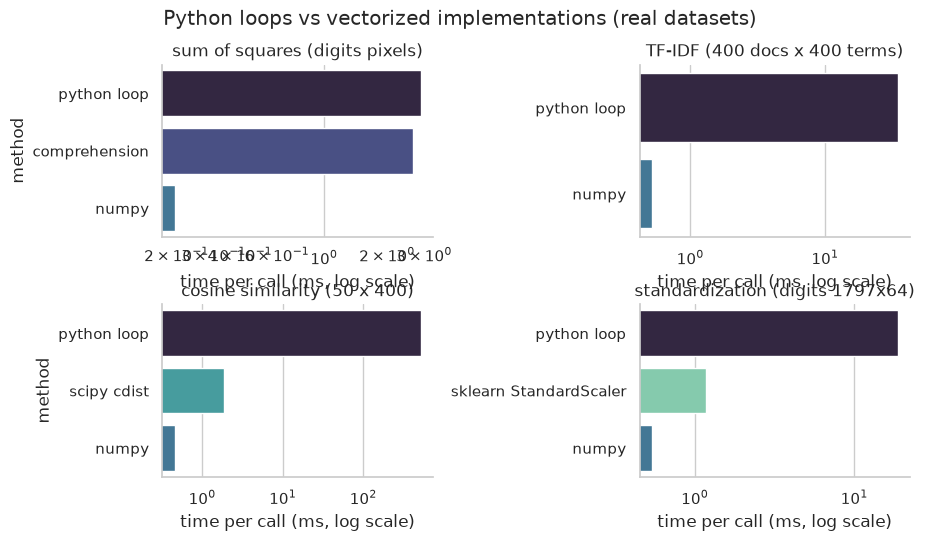

In [12]:
plot_df = pd.DataFrame([
    {"benchmark": b, "method": m, "ms": s * 1e3}
    for b, methods in BENCH.items() for m, s in methods.items()
])
g = sns.catplot(data=plot_df, x="ms", y="method", col="benchmark", kind="bar",
                col_wrap=2, sharex=False, sharey=False, height=2.6, aspect=1.8, palette="mako",
                hue="method", legend=False)
for ax in g.axes.flat:
    ax.set_xscale("log"); ax.set_xlabel("time per call (ms, log scale)")
g.set_titles("{col_name}")
g.figure.suptitle("Python loops vs vectorized implementations (real datasets)", y=1.03)
plt.show()

### Regras de ouro da vectorization

1. **Pense em colunas, não em linhas** — substitua `for i in range(n)` por operações sobre eixos (`axis=0/1`).
2. **Use broadcasting** — `(n, m) - (m,)` aplica a operação a cada linha sem copiar dados.
3. **Prefira produtos matriciais** (`@`) para similaridades e somas ponderadas — usam BLAS.
4. **Evite converter para listas** (`.tolist()`) no meio do pipeline.
5. **Cuidado com divisão por zero** (`np.where`, `np.clip`) — o loop tratava isso com `if`.
6. **Valide sempre** com `np.allclose` contra a versão de referência.
7. **Atenção à memória** — vectorizar pode criar arrays intermediários grandes (ex.: matriz densa *vs.* esparsa).

In [13]:
names = pd.concat([titanic["who"].astype(str) + " " + titanic["embark_town"].fillna("unknown")] * 50,
                  ignore_index=True)        # 891 real rows replicated x50 to get measurable timings
names_list = names.tolist()
names_np = names.to_numpy(dtype=str)

def upper_len_loop(values):
    """Uppercase strings and compute lengths with a loop."""
    up, ln = [], []
    for s in values:
        up.append(s.upper()); ln.append(len(s))
    return up, ln

def upper_len_pandas(s: pd.Series):
    return s.str.upper(), s.str.len()

def upper_len_npchar(a: np.ndarray):
    return np.char.upper(a), np.char.str_len(a)

up_l, len_l = upper_len_loop(names_list)
up_p, len_p = upper_len_pandas(names)
up_n, len_n = upper_len_npchar(names_np)
assert up_l == up_p.tolist() == up_n.tolist() and len_l == len_p.tolist() == len_n.tolist()

t = {"python loop": bench(lambda: upper_len_loop(names_list)),
     "pandas .str": bench(lambda: upper_len_pandas(names)),
     "numpy.char": bench(lambda: upper_len_npchar(names_np))}
BENCH["string ops (titanic, 44.5k strings)"] = t
for k, v in t.items():
    print(f"{k:<12}: {v*1e3:7.2f} ms")
print("\n📌 For strings, NumPy/pandas still loop over Python objects internally — gains are small or negative.")

python loop :    2.81 ms
pandas .str :   10.01 ms
numpy.char  :   15.87 ms

📌 For strings, NumPy/pandas still loop over Python objects internally — gains are small or negative.


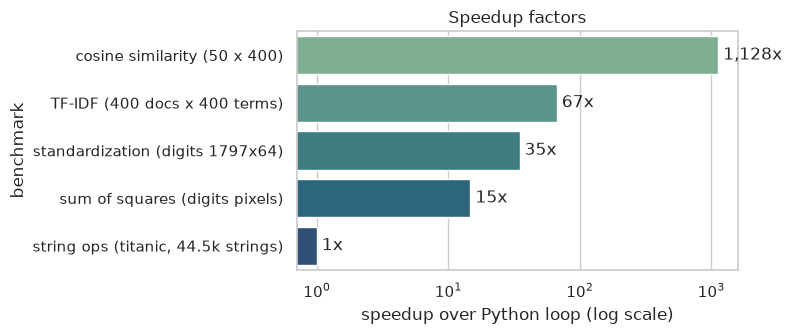

,benchmark,baseline (ms),best method,best (ms),speedup
0,cosine similarity (50 x 400),515.2982,numpy,0.4569,1127.8186
1,TF-IDF (400 docs x 400 terms),34.7066,numpy,0.5191,66.8641
2,standardization (digits 1797x64),18.7367,numpy,0.5384,34.8018
3,sum of squares (digits pixels),2.8802,numpy,0.1957,14.7167
4,"string ops (titanic, 44.5k strings)",2.8149,python loop,2.8149,1.0000


In [14]:
speedups = pd.DataFrame([
    {"benchmark": b, "baseline (ms)": m["python loop"] * 1e3,
     "best method": min(m, key=m.get), "best (ms)": min(m.values()) * 1e3,
     "speedup": m["python loop"] / min(m.values())}
    for b, m in BENCH.items()
]).sort_values("speedup", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(data=speedups, x="speedup", y="benchmark", hue="benchmark", palette="crest", legend=False, ax=ax)
ax.set_xscale("log"); ax.set_xlabel("speedup over Python loop (log scale)")
for i, v in enumerate(speedups["speedup"]):
    ax.text(v, i, f" {v:,.0f}x", va="center")
ax.set_title("Speedup factors"); plt.tight_layout(); plt.show()
speedups

## Seção 4 — Otimização de Pandas

O pandas é construído sobre NumPy, então as mesmas regras valem: **operações vetorizadas em colunas** são rápidas; qualquer coisa que execute uma função Python **por linha** (`apply(axis=1)`, `iterrows`) é lenta.

Como `tips` tem só 244 linhas, eu replico o dataset real 400× (~97 mil linhas) para que os tempos sejam mensuráveis — a distribuição dos valores continua sendo a do dataset original.

In [15]:
tips_big = pd.concat([tips] * 400, ignore_index=True)
print(f"tips_big: {tips_big.shape}")

def tip_pct_apply(df):
    return df.apply(lambda r: r["tip"] / r["total_bill"] * 100, axis=1)

def tip_pct_vectorized(df):
    return df["tip"] / df["total_bill"] * 100

def tip_pct_numpy(df):
    return df["tip"].to_numpy() / df["total_bill"].to_numpy() * 100

assert np.allclose(tip_pct_apply(tips_big.head(2000)), tip_pct_vectorized(tips_big.head(2000)))

t = {"apply(axis=1)": bench(lambda: tip_pct_apply(tips_big), number=1, repeat=2),
     "vectorized Series": bench(lambda: tip_pct_vectorized(tips_big), number=50),
     ".to_numpy()": bench(lambda: tip_pct_numpy(tips_big), number=50)}
for k, v in t.items():
    print(f"{k:<18}: {v*1e3:9.3f} ms  ({t['apply(axis=1)']/v:7.0f}x)")

# Conditional logic: np.where / np.select instead of apply with if/else
size_label = np.select([tips_big["size"] <= 2, tips_big["size"] <= 4], ["small", "medium"], "large")
pd.Series(size_label).value_counts()

tips_big: (97600, 7)


apply(axis=1)     :   381.719 ms  (      1x)
vectorized Series :     0.218 ms  (   1748x)
.to_numpy()       :     0.086 ms  (   4457x)


small     64000
medium    30000
large      3600
Name: count, dtype: int64

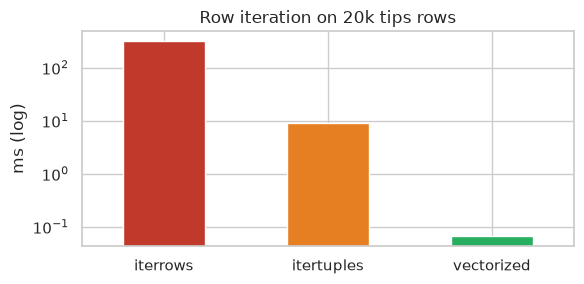

,ms,speedup_vs_iterrows
iterrows,317.2811,1.0000
itertuples,9.0657,34.9979
vectorized,0.0680,4665.7639


In [16]:
sample = tips_big.head(20_000)

def total_iterrows(df):
    return sum(row["tip"] * row["size"] for _, row in df.iterrows())

def total_itertuples(df):
    return sum(row.tip * row.size for row in df.itertuples(index=False))

def total_vectorized(df):
    return float((df["tip"] * df["size"]).sum())

assert np.isclose(total_iterrows(sample), total_vectorized(sample))
assert np.isclose(total_itertuples(sample), total_vectorized(sample))

t = {"iterrows": bench(lambda: total_iterrows(sample), number=1, repeat=2),
     "itertuples": bench(lambda: total_itertuples(sample), number=3),
     "vectorized": bench(lambda: total_vectorized(sample), number=50)}
it_df = pd.Series({k: v * 1e3 for k, v in t.items()}, name="ms")
ax = it_df.plot.bar(color=["#c0392b", "#e67e22", "#27ae60"], figsize=(6, 3), rot=0, logy=True)
ax.set_ylabel("ms (log)"); ax.set_title("Row iteration on 20k tips rows")
plt.tight_layout(); plt.show()
it_df.to_frame().assign(speedup_vs_iterrows=lambda d: d["ms"].max() / d["ms"])

In [17]:
titanic_big = pd.concat([titanic] * 100, ignore_index=True)
obj_cols = titanic_big.select_dtypes(include="object").columns.tolist()

def optimize_dtypes(df: pd.DataFrame, max_unique_ratio: float = 0.5) -> pd.DataFrame:
    """Convert low-cardinality object columns to category and downcast numerics."""
    out = df.copy()
    for col in out.select_dtypes(include="object"):
        if out[col].nunique() / len(out) < max_unique_ratio:
            out[col] = out[col].astype("category")
    for col in out.select_dtypes(include="integer"):
        out[col] = pd.to_numeric(out[col], downcast="integer")
    for col in out.select_dtypes(include="float"):
        out[col] = pd.to_numeric(out[col], downcast="float")
    return out

titanic_opt = optimize_dtypes(titanic_big)
mem_cmp = pd.DataFrame({
    "before_KB": titanic_big.memory_usage(deep=True) / 1024,
    "after_KB": titanic_opt.memory_usage(deep=True) / 1024,
    "dtype_after": titanic_opt.dtypes.astype(str),
}).drop(index="Index")
mem_cmp["reduction"] = 1 - mem_cmp["after_KB"] / mem_cmp["before_KB"]
print(f"Total: {mem_cmp['before_KB'].sum()/1024:.1f} MB -> {mem_cmp['after_KB'].sum()/1024:.1f} MB")

t_obj = bench(lambda: titanic_big.groupby("embark_town")["fare"].mean(), number=20)
t_cat = bench(lambda: titanic_opt.groupby("embark_town", observed=True)["fare"].mean(), number=20)
print(f"groupby object: {t_obj*1e3:.2f} ms | groupby category: {t_cat*1e3:.2f} ms")
mem_cmp.sort_values("reduction", ascending=False)

Total: 30.5 MB -> 1.8 MB


groupby object: 3.31 ms | groupby category: 1.08 ms


,before_KB,after_KB,dtype_after,reduction
embark_town,5869.4336,87.3135,category,0.9851
sex,5369.0430,87.2383,category,0.9838
who,5289.8438,87.2969,category,0.9835
alive,5167.0898,87.2334,category,0.9831
embarked,5041.6016,87.2871,category,0.9827
parch,696.0938,87.0117,int8,0.8750
sibsp,696.0938,87.0117,int8,0.8750
survived,696.0938,87.0117,int8,0.8750
pclass,696.0938,87.0117,int8,0.8750
age,696.0938,348.0469,float32,0.5000


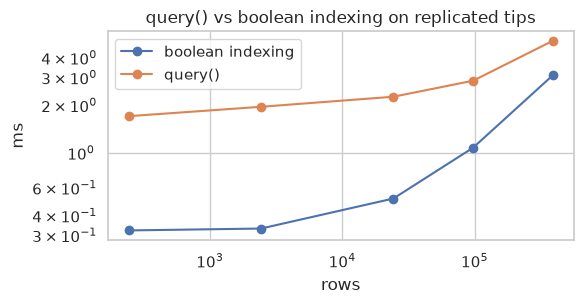

,boolean indexing,query()
rows,,
244,0.3225,1.7056
2440,0.3315,1.9559
24400,0.5136,2.2648
97600,1.0772,2.8604
390400,3.0956,5.1165


In [18]:
cond_bool = lambda df: df[(df["total_bill"] > 20) & (df["day"].isin(["Sat", "Sun"])) & (df["size"] >= 3)]
cond_query = lambda df: df.query("total_bill > 20 and day in ['Sat', 'Sun'] and size >= 3")

pd.testing.assert_frame_equal(cond_bool(tips_big), cond_query(tips_big))

rows = []
for factor in [1, 10, 100, 400, 1600]:
    df = pd.concat([tips] * factor, ignore_index=True)
    rows.append({"rows": len(df),
                 "boolean indexing": bench(lambda: cond_bool(df), number=10) * 1e3,
                 "query()": bench(lambda: cond_query(df), number=10) * 1e3})
q_df = pd.DataFrame(rows).set_index("rows")
ax = q_df.plot(marker="o", logx=True, logy=True, figsize=(6, 3.2))
ax.set_ylabel("ms"); ax.set_title("query() vs boolean indexing on replicated tips")
plt.tight_layout(); plt.show()
q_df

### Checklist de otimização no pandas

- [ ] Evitar `apply(axis=1)` e `iterrows()` — usar operações de coluna, `np.where`, `np.select`.
- [ ] Se precisar iterar, usar `itertuples()` (muito mais rápido que `iterrows`).
- [ ] Converter colunas de texto com poucos valores únicos para `category`.
- [ ] Fazer *downcast* de numéricos (`int64 → int8/16`, `float64 → float32`) quando a precisão permitir.
- [ ] `query()` melhora a legibilidade; com `numexpr` instalado pode ganhar em DataFrames grandes, mas em tabelas pequenas tem *overhead* de parsing.
- [ ] Ler só as colunas necessárias (`usecols`) e definir `dtype` já no `read_csv`.
- [ ] Medir com `memory_usage(deep=True)` — sem `deep=True` strings não são contadas.

## Seção 5 — Algoritmos e estruturas de dados

Nenhuma micro-otimização compensa um algoritmo com complexidade errada. Em NLP isso aparece o tempo todo:

| Operação | `list` | `dict` / `set` |
|---|---|---|
| `x in container` | **O(n)** | **O(1)** médio (hash) |
| deduplicar | O(n²) ingênuo | O(n) |
| top-N de n itens | `sorted` O(n log n) | `heapq.nlargest` O(n log N) |

Vocabulary size: 20,054 words


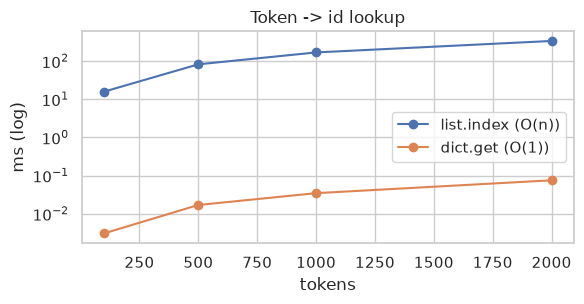

,list.index (O(n)),dict.get (O(1)),speedup
tokens,,,
100,15.8988,0.0031,5177.9502
500,82.6236,0.0170,4857.0237
1000,169.2205,0.0347,4876.7297
2000,338.2050,0.0755,4482.2460


In [19]:
vocab_list = sorted(freqs)                       # real vocabulary from the corpus
vocab_dict = {w: i for i, w in enumerate(vocab_list)}
vocab_set = set(vocab_list)
queries = tokenize(" ".join(corpus[:20]))[:2000] # real tokens to look up

def lookup_list(tokens):
    return [vocab_list.index(t) if t in vocab_list else -1 for t in tokens]

def lookup_dict(tokens):
    return [vocab_dict.get(t, -1) for t in tokens]

assert lookup_list(queries[:200]) == lookup_dict(queries[:200])

rows = []
for n in [100, 500, 1000, 2000]:
    q = queries[:n]
    rows.append({"tokens": n,
                 "list.index (O(n))": bench(lambda: lookup_list(q), number=1, repeat=2) * 1e3,
                 "dict.get (O(1))": bench(lambda: lookup_dict(q), number=20) * 1e3})
lk = pd.DataFrame(rows).set_index("tokens")
print(f"Vocabulary size: {len(vocab_list):,} words")
ax = lk.plot(marker="o", logy=True, figsize=(6, 3.2), title="Token -> id lookup")
ax.set_ylabel("ms (log)"); plt.tight_layout(); plt.show()
lk.assign(speedup=lk.iloc[:, 0] / lk.iloc[:, 1])

In [20]:
# Real corpus lines contain many duplicates (signatures, blank-ish lines, separators)
lines = [ln.strip().lower() for doc in corpus for ln in doc.splitlines() if ln.strip()]
print(f"{len(lines):,} non-empty lines")

def dedup_list(items):
    seen = []
    for x in items:
        if x not in seen:
            seen.append(x)
    return seen

def dedup_set_ordered(items):
    return list(dict.fromkeys(items))            # O(n), preserves first-seen order

subset = lines[:5000]
assert dedup_list(subset) == dedup_set_ordered(subset)
unique_all = dedup_set_ordered(lines)
print(f"Unique lines: {len(unique_all):,} ({1 - len(unique_all)/len(lines):.1%} duplicates)")

t_list = bench(lambda: dedup_list(subset), number=1, repeat=2)
t_set = bench(lambda: dedup_set_ordered(subset), number=20)
print(f"5k lines -> list: {t_list*1e3:.1f} ms | dict.fromkeys: {t_set*1e3:.3f} ms | {t_list/t_set:.0f}x")

# Set algebra: vocabulary overlap between newsgroup categories
cat_vocab = {name: set() for name in news.target_names}
for doc, tgt in zip(news.data, news.target):
    cat_vocab[news.target_names[tgt]].update(tokenize(doc))
a, b = cat_vocab["rec.autos"], cat_vocab["sci.space"]
print(f"Jaccard(rec.autos, sci.space) = {len(a & b) / len(a | b):.3f}; "
      f"autos-only examples: {sorted(a - b, key=lambda w: -freqs[w])[:8]}")

32,031 non-empty lines
Unique lines: 30,043 (6.2% duplicates)


5k lines -> list: 82.5 ms | dict.fromkeys: 0.177 ms | 465x
Jaccard(rec.autos, sci.space) = 0.262; autos-only examples: ['sgi', 'dealer', 'ford', 'tires', 'hp', 'autos', 'brake', 'wheel']


sorted()[:N]        :    2.09 ms
heapq.nlargest      :    0.88 ms
Counter.most_common :    1.20 ms


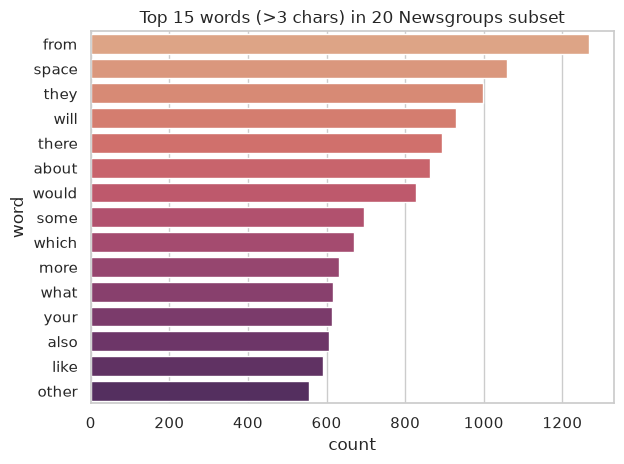

In [21]:
content_freqs = Counter({w: c for w, c in freqs.items() if len(w) > 3})
N = 15

def top_sorted(counter, n):
    return sorted(counter.items(), key=lambda kv: kv[1], reverse=True)[:n]

def top_heapq(counter, n):
    return heapq.nlargest(n, counter.items(), key=lambda kv: kv[1])

assert [c for _, c in top_sorted(content_freqs, N)] == [c for _, c in top_heapq(content_freqs, N)]

t = {"sorted()[:N]": bench(lambda: top_sorted(content_freqs, N), number=10),
     "heapq.nlargest": bench(lambda: top_heapq(content_freqs, N), number=10),
     "Counter.most_common": bench(lambda: content_freqs.most_common(N), number=10)}
for k, v in t.items():
    print(f"{k:<20}: {v*1e3:7.2f} ms")

top = pd.DataFrame(content_freqs.most_common(N), columns=["word", "count"])
ax = sns.barplot(data=top, x="count", y="word", hue="word", palette="flare", legend=False)
ax.set_title(f"Top {N} words (>3 chars) in 20 Newsgroups subset"); plt.tight_layout(); plt.show()

### Quando a estrutura de dados faz diferença

- **Vocabulário / stopwords / léxicos** → sempre `set` ou `dict` (lookup O(1)). A diferença cresce linearmente com o tamanho do vocabulário.
- **Deduplicação preservando ordem** → `dict.fromkeys(items)`.
- **Contagem** → `collections.Counter` (implementado em C para `update` de iteráveis).
- **Top-N com N ≪ n** → `heapq.nlargest` / `Counter.most_common(N)` (que usa `heapq` internamente).
- **Comparação de vocabulários** → álgebra de conjuntos (`&`, `|`, `-`) e índice de Jaccard.

📌 Em Linguística de Corpus isso é rotina: listas de frequência, perfis lexicais e comparação de vocabulário entre gêneros/registros dependem exatamente dessas operações.

## Seção 6 — Profiling de um pipeline de ML completo

Agora junto tudo: um pipeline scikit-learn real com `load_digits` (`StandardScaler → PCA → SVC`), avaliado com validação cruzada. Perguntas:

1. Qual etapa domina o tempo: pré-processamento, redução de dimensionalidade ou o classificador?
2. Dá para reduzir o custo **sem perder acurácia**?

In [22]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

X_tr, X_te, y_tr, y_te = train_test_split(digits.data, digits.target, test_size=0.25,
                                          random_state=42, stratify=digits.target)

def make_pipeline(n_components=None, clf=None) -> Pipeline:
    """Scaler -> PCA -> classifier pipeline."""
    return Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components, random_state=42)),
        ("clf", clf if clf is not None else SVC(C=10, gamma="scale")),
    ])

baseline = make_pipeline()
t0 = time.perf_counter()
baseline.fit(X_tr, y_tr)
fit_s = time.perf_counter() - t0
print(f"Baseline (all 64 PCA components) fit: {fit_s*1e3:.1f} ms | test accuracy: {baseline.score(X_te, y_te):.4f}")

# Per-step timing by fitting each step manually
step_times, Xt = {}, X_tr
for name, step in baseline.steps:
    t0 = time.perf_counter()
    if hasattr(step, "transform"):
        Xt = step.fit(Xt, y_tr).transform(Xt)
    else:
        step.fit(Xt, y_tr)
    step_times[name] = (time.perf_counter() - t0) * 1e3
pd.Series(step_times, name="fit ms").to_frame()

Baseline (all 64 PCA components) fit: 40.0 ms | test accuracy: 0.9800


,fit ms
scaler,1.2891
pca,1.8521
clf,36.1838


In [23]:
pipe_profiler = cProfile.Profile()
pipe_profiler.enable()
cv_scores = cross_val_score(make_pipeline(), digits.data, digits.target, cv=5)
pipe_profiler.disable()
print(f"5-fold CV accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}\n")

s = io.StringIO()
ps = pstats.Stats(pipe_profiler, stream=s).strip_dirs().sort_stats("tottime")
ps.print_stats(10)
report = s.getvalue()
print(report[report.find("ncalls") - 1:][:2200])

# Aggregate cumulative time by sklearn stage
stage_rows = [{"func": f[2], "file": f[0], "cumtime": v[3]} for f, v in ps.stats.items()]
stage_df = pd.DataFrame(stage_rows)
for key in ["fit", "transform", "predict", "score"]:
    hits = stage_df[stage_df["func"] == key].sort_values("cumtime", ascending=False).head(4)
    print(f"{key:>9}: " + ", ".join(f"{r.file}:{r.cumtime:.3f}s" for r in hits.itertuples()))

5-fold CV accuracy: 0.9510 ± 0.0091

 ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        5    0.745    0.149    0.745    0.149 _base.py:344(_dense_fit)
        5    0.083    0.017    0.083    0.017 _base.py:475(_dense_predict)
       10    0.007    0.001    0.007    0.001 _base.py:157(_transform)
      112    0.003    0.000    0.003    0.000 {method 'reduce' of 'numpy.ufunc' objects}
     1542    0.002    0.000    0.003    0.000 inspect.py:1790(_shadowed_dict)
        5    0.002    0.000    0.002    0.000 linalg.py:1348(eigh)
       93    0.002    0.000    0.005    0.000 inspect.py:2331(_signature_from_function)
        5    0.002    0.000    0.005    0.001 _pca.py:544(_fit_full)
     7167    0.001    0.000    0.002    0.000 {built-in method builtins.isinstance}
      709    0.001    0.000    0.002    0.000 inspect.py:2669(__init__)



      fit: pipeline.py:0.782s, _base.py:0.754s, _data.py:0.007s
transform: _data.py:0.005s, _base.py:0.004s
  predict: _base.p

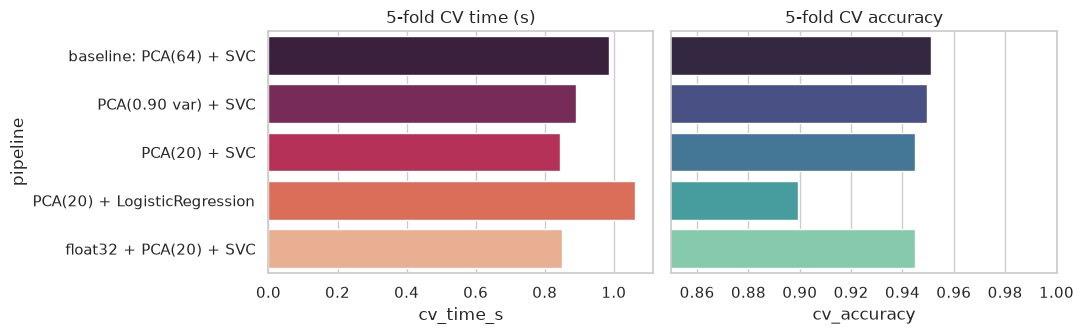

,pipeline,pca_components,cv_accuracy,cv_time_s,speedup
0,baseline: PCA(64) + SVC,64,0.9510,0.9858,1.0000
1,PCA(0.90 var) + SVC,31,0.9494,0.8895,1.1083
2,PCA(20) + SVC,20,0.9449,0.8432,1.1691
3,PCA(20) + LogisticRegression,20,0.8993,1.0618,0.9284
4,float32 + PCA(20) + SVC,20,0.9449,0.8507,1.1588


In [24]:
candidates = {
    "baseline: PCA(64) + SVC": make_pipeline(None),
    "PCA(0.90 var) + SVC": make_pipeline(0.90),
    "PCA(20) + SVC": make_pipeline(20),
    "PCA(20) + LogisticRegression": make_pipeline(20, LogisticRegression(max_iter=2000)),
    "float32 + PCA(20) + SVC": make_pipeline(20),
}

results = []
for name, pipe in candidates.items():
    Xd = digits.data.astype(np.float32) if name.startswith("float32") else digits.data
    t0 = time.perf_counter()
    scores = cross_val_score(pipe, Xd, digits.target, cv=5)
    elapsed = time.perf_counter() - t0
    n_comp = pipe.fit(Xd, digits.target).named_steps["pca"].n_components_
    results.append({"pipeline": name, "pca_components": n_comp,
                    "cv_accuracy": scores.mean(), "cv_time_s": elapsed})

res_df = pd.DataFrame(results)
res_df["speedup"] = res_df.loc[0, "cv_time_s"] / res_df["cv_time_s"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
sns.barplot(data=res_df, x="cv_time_s", y="pipeline", hue="pipeline", palette="rocket", legend=False, ax=axes[0])
axes[0].set_title("5-fold CV time (s)")
sns.barplot(data=res_df, x="cv_accuracy", y="pipeline", hue="pipeline", palette="mako", legend=False, ax=axes[1])
axes[1].set_xlim(0.85, 1.0); axes[1].set_title("5-fold CV accuracy")
plt.tight_layout(); plt.show()
res_df.round(4)

### Lições aprendidas e próximos passos

**O que o profiling mostrou**
- No pipeline de dígitos, o custo é dominado pelo **classificador** (SVC: `fit`/`predict` com kernel RBF), não pelo `StandardScaler`.
- Reduzir a dimensionalidade com PCA (64 → ~20 componentes) diminui o custo do SVC mantendo a acurácia praticamente igual — confira a tabela acima, pois os números variam a cada máquina.
- `float32` reduz memória pela metade, mas **não** acelerou o SVC nesta execução: o libsvm trabalha internamente em `float64`, então a conversão só adiciona custo. Otimização sem medição pode piorar o resultado!
- Trocar SVC por `LogisticRegression` não foi vantajoso aqui: mais lento e com acurácia menor — o profiling evita trocas "intuitivas" ruins.

**Lições gerais do dia**
1. *Medir primeiro* — `cProfile` para achar o gargalo, `timeit` para comparar soluções.
2. *Vectorization* traz os maiores ganhos numéricos (de dezenas a milhares de vezes); para strings não houve ganho — o loop simples foi o mais rápido nesta execução.
3. *Estrutura de dados certa* (`set`/`dict`/`heapq`) muda a complexidade, não só a constante.
4. *Memória também é performance* — matrizes esparsas, `category` e *downcast*.
5. *Sempre validar* que a versão otimizada produz o mesmo resultado (`np.allclose`, `assert_frame_equal`).

**Próximos passos**
- Testar `line_profiler`, `memory_profiler`, `py-spy` e `scalene` em um ambiente dedicado.
- Explorar compilação JIT (`numba`) e backends alternativos (`polars`, `pyarrow`).
- Aplicar esse fluxo ao perfil de complexidade textual de produções de aprendizes de inglês.

## Resumo

| Seção | Técnica | Principal resultado |
|---|---|---|
| 1 | `timeit`, `cProfile`, `pstats` | gargalo localizado em lookup em lista |
| 2 | *line profiler* com `sys.settrace`, `tracemalloc`, `getsizeof` | matriz densa de BoW é o maior consumidor de memória; CSR economiza ordens de grandeza |
| 3 | NumPy vectorization | TF-IDF, cosseno e normalização com *speedups* de ~50× a ~1000× (dependente da máquina) |
| 4 | pandas | `apply`/`iterrows` são os vilões; `category` reduz memória |
| 5 | estruturas de dados | `dict`/`set` O(1) vs `list` O(n) em vocabulário NLP |
| 6 | pipeline sklearn | SVC domina o custo; PCA reduz tempo sem perder acurácia |

**Referências:** documentação oficial de [`timeit`](https://docs.python.org/3/library/timeit.html), [`cProfile`/`pstats`](https://docs.python.org/3/library/profile.html), [`tracemalloc`](https://docs.python.org/3/library/tracemalloc.html), [NumPy broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html), [pandas — Enhancing performance](https://pandas.pydata.org/docs/user_guide/enhancingperf.html) e [scikit-learn — Computational performance](https://scikit-learn.org/stable/computing/computational_performance.html).